# Lecture 4 - Basic Filtering

The most basic filtering operation is removal of noise.  A typical scenario is that there is an original signal $x$ which is perhaps a person singing.  We listen to the radio broadcast, where we hear $y=x+n$ where $n$ is noise added by the transmission process. The goal of a filter in the radio receiver is to reconstruct $\hat{x}$ from $y$ so that $\| \hat{x} - x \|$ is minimized.  

The noise may be independent of $x$ (as in added Gaussian white noise) or dependent on $x$ (if there is a predictable distortion), or it could be both.  An example of independent noise is hiss or hum due to electrical interference. An example of a predictable distortion might be a compression operation such as $y(t)=\log{x(t)}$ that we need to undo using a (nonlinear) decompression operation $\hat{x}(t) = e^{y(t)}$.

In linear filtering, all we can do is to hope that $x$ and $n$ have different frequency spectra, so that we can remove $n$ by linear filtering.  For example, if $x$ is low-frequency and $n$ is high-frequency, then a low-pass filter will attenuate $n$ more than $x$.  This will not work when the noise depends on $x$, if the noise shares frequencies with $x$, or if there is a nonlinear distortion.  

The overall structure will be that we create a network $F$ to approximate the true input from the noisy data, so that $\hat{x} = F(y)$ where $y$ is the noisy or distorted data, and $\hat{x}$ is our estimate of the true signal $x$.  We can write $\hat{x} = F(N(x))$ to emphasize that in some sense the network $F$ is trying to be the inverse of the noise $N$.

In general, the noise may not be memoryless.  Memoryless means that $y(t) = N[x(t)]$ so each sample depends only on the input at that time.  But most distortion is not memoryless.  For instance, an echo might be $y(t) = x(t-t_{\rm echo})$ where $t_{\rm echo}$ is the echo time.  So the inputs to the network will generally be a series of lagged values $<y(t), y(t-1), \ldots y(t-T)>$.

Note that although memoryless distortion (eg: $y(t)=\log{x(t)}$) only requires a memoryless filter (eg: $\hat{x}(t) = e^{y(t)}$), memoryless noise (eg: $y(t) = x(t) + n(t)$) may require a filter with memory. This is true even for linear filters, because if we are removing high-frequency noise by low-pass filtering $y$, then we need lagged values to calculate the FIR or IIR filters.  The reason this is the case is that the only way to remove noise from a signal is to know something about the signal (otherwise how do you know the noise isn't part of the signal?).  For low-pass filtering, you know the signal is low frequency. For music, you know that western music tends to play on one of 12 notes in each octave.  For estimation of speed, you know that airplanes cannot change speed instantaneously.  So usually our knowledge of the signals we want to estimate includes something about their time-course, smoothness, patterns, or acceptable values over time. So a network could learn these patterns in order to discriminate signal from noise.

This is similar to the timeseries prediction we did in Lecture1, where you try to predict the next value in the series.  If we assume that noise is unpredictable, then the only thing that can be predicted must be signal.  If we assume that the predictor for the signal will be a poor predictor for the noise (because they do not look the same) then a predictor for the signal may ignore the noise.  On the other hand, if the noise is predictable (a motor, background music, etc.) then you can predict the noise and subtract it from the signal.




In [ ]:
# Needed imports
import numpy as np
import pandas as pd
from IPython.display import Audio
from scipy.io import wavfile   # this is for playing audio
import matplotlib.pyplot as plt
import seaborn as sns

Create a simple sound as a combination of two sin waves.


In [ ]:
# Create a sound
framerate = 44100
t = np.linspace(0,5,framerate*5)
data = np.sin(2*np.pi*220*t) + np.sin(2*np.pi*224*t)

In [ ]:
# Generate a player for mono sound
#NOTE: do not put a semicolon after the Audio() call or you will not see the player.
Audio(data,rate=framerate)

For more complex sounds you will need to load a sound file.  WAV files are the easiest to work with.  Python, matlab, the Mac "Music" app, and many others can create wav files.  There are also some tools that will convert the more common mp3 format into wav.

In [ ]:
    # How to load a sound file from GitHub
    # Note that you need the link to the "raw" file on github or the file format will fail
    !wget https://github.com/R6500/Python-bits/raw/master/Colaboratory/Sounds/Bicycle%20bell%203.wav
    #the file will end up at the top level of the local (colab) directory
    !ls
    data = wavfile.read('Bicycle bell 3.wav')
    Audio(data[1], rate=data[0])  #data[0] is the sample rate, data[1] is the (mono) data


--2023-10-15 13:50:24--  https://github.com/R6500/Python-bits/raw/master/Colaboratory/Sounds/Bicycle%20bell%203.wav
Resolving github.com (github.com)... 140.82.113.4
Connecting to github.com (github.com)|140.82.113.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/R6500/Python-bits/master/Colaboratory/Sounds/Bicycle%20bell%203.wav [following]
--2023-10-15 13:50:25--  https://raw.githubusercontent.com/R6500/Python-bits/master/Colaboratory/Sounds/Bicycle%20bell%203.wav
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1869076 (1.8M) [audio/wav]
Saving to: ‘Bicycle bell 3.wav.3’

Bicycle bell 3.wav. 100%[===================>]   1.78M  --.-KB/s    in 0.07s   

2023-10-15 13:50:25 (26.9 MB/s) - ‘Bicyc

<ipython-input-78-5f96d3b39c43>:6: WavFileWarning: Chunk (non-data) not understood, skipping it.
  data = wavfile.read('Bicycle bell 3.wav')


In [ ]:
#For your own files, it is easier to read them from your own google drive
# this will mount your google drive (after asking permission) with all your directories under the "drive" tab
# to see them, click on the small folder icon in the left margin of the jupyter notebook
# then look under the drive/MyDrive subdirectory
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Download the BachDoubleViolinConcerto.wav file from canvas/files
#   put this file into your google drive in some subdirectory
#   for example, mine is in the directory "Colab Notebooks"
data = wavfile.read('/content/drive/MyDrive/Colab Notebooks/BachDoubleViolinConcerto.wav')



Once the file is saved in the **virtual machine**, it can be read on a numpy array and decoded as sound information

In [ ]:
# for Mono recordings, data[0] is the sample rate and data[1] is the byte sequence of sound
framerate = data[0]
sounddata = data[1]
#create the timestamps
time      = np.arange(0,len(sounddata))/framerate

# Show information about the object
print('Sample rate:',framerate,'Hz')
print('Total time:',len(sounddata)/framerate,'s')

Sample rate: 22050 Hz
Total time: 236.7190022675737 s


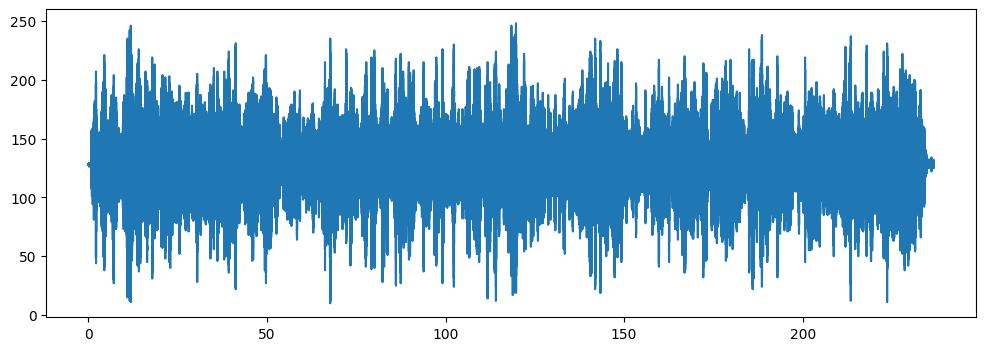

In [ ]:
plt.figure(figsize=(12,4))
plt.plot(time, sounddata);

Surprisingly, Google Colab seems to have access to the speakers of your computer.  

In [ ]:
#Play the sound
Audio(sounddata,rate=framerate)

In [ ]:
#get 7 second of data.  framerate is the number of samples in each second
start_data = int(1*framerate)
end_data = 8*framerate
x = sounddata[start_data:end_data]
t = time[start_data:end_data]
Audio(x, rate=framerate)

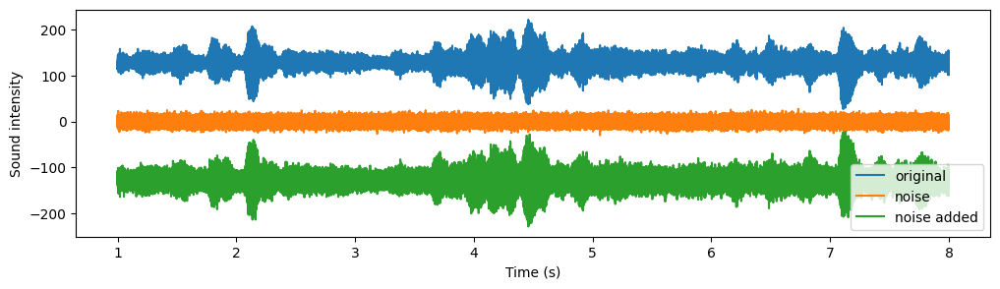

In [ ]:
#additive random Gaussian noise y=x+n
from numpy.random import default_rng
rng = default_rng()

rms = np.sqrt(np.mean((x-np.mean(x))**2))  #find the signal power for scaling the noise
noise = rng.standard_normal(len(x))*rms*0.4   #noise is gaussian 40% of signal rms power
plt.figure(figsize = (12,3))
plt.plot(t,x, label='original')
plt.plot(t,noise, label='noise')
plt.plot(t,noise-x, label='noise added')
plt.xlabel('Time (s)')
plt.ylabel('Sound intensity')
plt.legend()

noise_data = x+noise
Audio(noise_data, rate=framerate)

#Filtering starts here
(so does the homework for the other two cases.  see below)

In [ ]:
from tensorflow.python.keras.engine.base_layer_utils import uses_keras_history
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Reshape, Flatten
from tensorflow.keras.layers import LSTM
from tensorflow.keras.callbacks import EarlyStopping

from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator


In [ ]:
#create the series, dataframes, and training and validation sets
input_series = pd.Series(data=x, index = t)   #name='inputSeries',
input_frame = input_series.to_frame() #name='inputSeries')
noise_series = pd.Series(data=noise_data, index = t) #name='noiseSeries',
noise_frame = noise_series.to_frame() #name='noiseSeries')

input_frame.describe()



,0
count,154350.000000
mean,127.998665
std,15.864628
min,27.000000
25%,120.000000
50%,128.000000
75%,136.000000
max,221.000000


In [ ]:
#create the training and test sets
validation_size = int(0.1*len(x))
validation_start = len(x)-validation_size
xTrain = input_frame.iloc[:validation_start]
xTest = input_frame.iloc[validation_start:]
noiseTrain=noise_frame.iloc[:validation_start]
noiseTest = noise_frame.iloc[validation_start:]

#preprocessing; scaling
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(xTrain)
xTrain = scaler.transform(xTrain)  #converts to a numpy array
xTest = scaler.transform(xTest)
noiseTrain = scaler.transform(noiseTrain)
noiseTest = scaler.transform(noiseTest)



In [ ]:
#create the data generators
#  note that the network input is the noisy signal, and the desired output is the clean signal
predict_length = int(0.005*framerate)  #5msec segments for prediction
pl2 = int(predict_length/2)  #used to offset the prediction to the middle of the sample

#the desired output is shifted pl2 to the right (by duplicating the first elements)
#  TimeSeriesGenerator always tries to predict the NEXT output after the end
#  By shifting pl2 to the right, we try to predict the MIDDLE output
#  This will be a non-causal filter (or a causal filter with a delay) but that's ok
trainGenerator = TimeseriesGenerator(noiseTrain, np.append(xTrain[:pl2],xTrain[:-pl2]), length=predict_length, batch_size=1)
validationGenerator = TimeseriesGenerator(noiseTest, np.append(xTest[:pl2],xTest[:-pl2]), length = predict_length, batch_size=1)
shortTrainGenerator = TimeseriesGenerator(noiseTrain[:1000], np.append(xTrain[:pl2],xTrain[:1000-pl2]), length=predict_length, batch_size=1)
shortValidationGenerator = TimeseriesGenerator(noiseTest[:1000], np.append(xTest[:pl2],xTest[:1000-pl2]), length = predict_length, batch_size=1)

#early stopping may not be needed, because the data length is so long we can use a small number of batches
early_stop = EarlyStopping(monitor='val_loss',patience=2)

In [ ]:
#create the network
n_features = 1

#will use two nonlinear layers so that we can capture second-order interactions between inputs in the first layer
model = Sequential()
use_LSTM = 0
if use_LSTM ==1:   #LSTM creates a dynamic model of the signal
  model.add(LSTM(20,activation='sigmoid', input_shape = (predict_length, n_features)))
else:
  model.add(Flatten(input_shape = (predict_length, n_features)))
model.add(Dense(10, activation='sigmoid'))  #we expect the predictor will be a smoother, so use smooth activation
model.add(Dense(5, activation = 'sigmoid'))
model.add(Dense(1))  #this is a single output linear network at the top to allow scaling to the correct output range
model.compile(optimizer='adam', loss='mse')  #mse because is a regression problem
model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_3 (Flatten)         (None, 110)               0         
                                                                 
 dense_9 (Dense)             (None, 10)                1110      
                                                                 
 dense_10 (Dense)            (None, 5)                 55        
                                                                 
 dense_11 (Dense)            (None, 1)                 6         
                                                                 
Total params: 1,171
Trainable params: 1,171
Non-trainable params: 0
_________________________________________________________________


138805/138805 [==============================] - 418s 3ms/step - loss: 9.2849e-04 - val_loss: 5.2200e-04


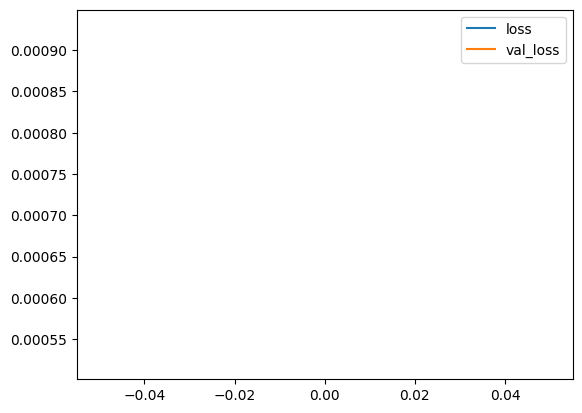

In [ ]:
#train the model
# only need a few epochs because each one has much data (22k data points per second)
if use_LSTM ==1:
  model.fit(shortTrainGenerator,epochs=1,   #use the short version because training is slow
                    validation_data=shortValidationGenerator,
                   callbacks=[early_stop])
else:
  model.fit(trainGenerator,epochs=1,
                    validation_data=validationGenerator,
                   callbacks=[early_stop])
losses = pd.DataFrame(model.history.history)
losses.plot();

890/890 [==============================] - 3s 3ms/step


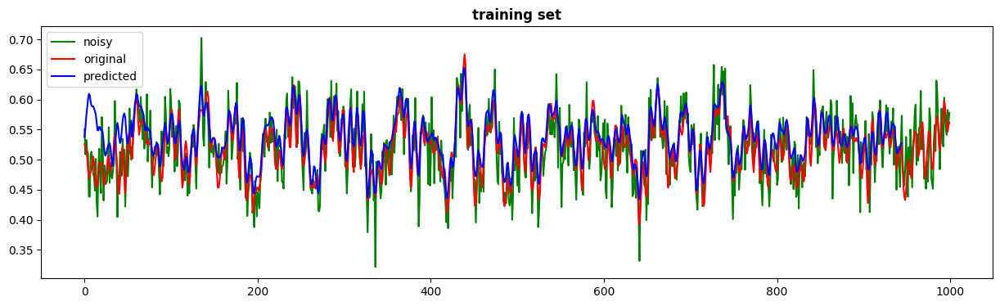

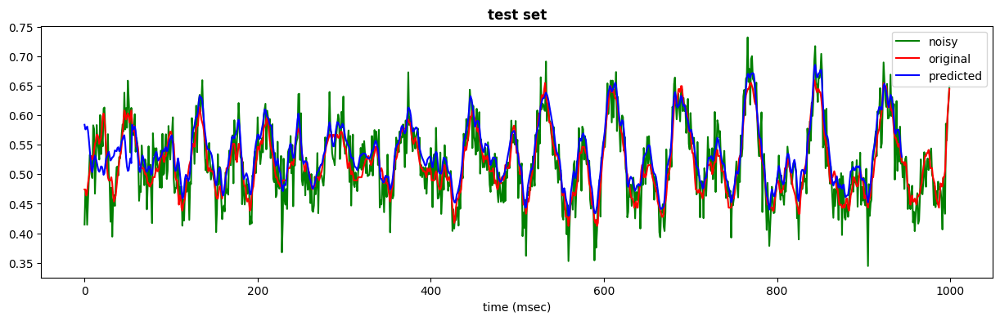

In [ ]:
#compare the predicted timeseries
predicted_outputs = model.predict(shortTrainGenerator)   #use short versions to speed this up
predicted_validation = model.predict(shortValidationGenerator)

plt.figure(figsize=(15,4), linewidth = 1)
plt.plot(noiseTrain[:1000],'g',label='noisy')  #input to the network
plt.plot(xTrain[:1000],'r',label='original')    #target output of the network (the clean signal)
#the network prediction is offset to the end of the segment; duplicate the first pl2 to fix the alignment
plt.plot(np.append(predicted_outputs[:pl2], predicted_outputs[:1000-pl2]),'b', label='predicted')
plt.title('training set',fontweight="bold")
plt.legend()

plt.figure(figsize=(15,4), linewidth = 1)
plt.plot(noiseTest[:1000],'g',label='noisy')
plt.plot(xTest[:1000],'r',label='original')
#the network prediction is offset to the end of the segment; duplicate the first pl2 to fix the alignment
plt.plot(np.append(predicted_validation[:pl2], predicted_validation[:1000-pl2]),'b', label='predicted')
plt.title('test set',fontweight="bold");
plt.xlabel('time (msec)')
plt.legend();



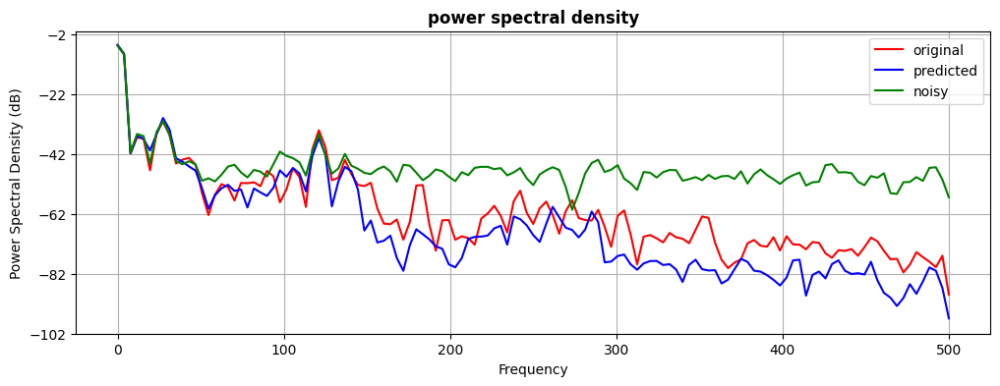

In [ ]:
#compare the power spectral densities
plt.figure(figsize=(12,4))
plt.psd(xTrain.ravel()[:1000], color='r', Fs=1000, scale_by_freq=0, label='original');
plt.psd(predicted_outputs.ravel()[:1000], Fs=1000, color = 'b', scale_by_freq=0, label='predicted');  #use ravel to make a horizontal array
plt.psd(noiseTrain.ravel()[:1000], Fs=1000, color = 'g', scale_by_freq=0, label='noisy');  #use ravel to make a horizontal array
plt.title('power spectral density',fontweight="bold");
plt.legend();

In [ ]:
#listen to a longer segment after filtering
predicted_music = model.predict(trainGenerator)
Audio(predicted_music.ravel(), rate=framerate)


138805/138805 [==============================] - 301s 2ms/step


In [ ]:
#here is the original (noisy) segment for comparison
Audio(noise_data, rate=framerate)

#Homework #3

Do headphone noise-cancellation for the mixture_data.  The situation is that you are trying to have a phone call with your friend, using an earphone to hear the call, but the person sitting next to you is playing loud music that is making it hard to hear.  You want the earphone to remove the music so you hear only what your friend is saying.  

The earphone is designed with a microphone on the outside, and another microphone on the inside (essentially inside your ear canal).  The microphone on the outside hears MusicData, while the microphone on the inside hears SpeechData+MusicData. It is actually a bit more difficult, because the music gets distorted as it is passing through the earphone, so on the inside you actually have SpeechData + f(MusicData) where $f()$ is an unknown distortion function.

Your job is to build a network $N$ that estimates f(MusicData) so that you can subtract this from the signal in your ear (by subtracting it from the signal driving the loudspeaker inside the headset).  The network has access to the two microphones, so it will try to approximate f(MusicData) from MusicData.  In other words, if x=MusicData, z=SpeechData, and $y=f(x) + z$, the network tries to learn to approximate $\hat{y}(x)$.  Of course, it cannot estimate the speech from your friend just by listening to the music from your neighbor, so even though the training data includes both speech and music, the network will (probably) only learn to approximate f(MusicData).  Once you have this, you subtract to get an estimate of the speech $\hat{z} = y-\hat{f}(x)$.

Turn in pdf plots of the original SpeechData $z$, the mixed data $y$, and your estimate $\hat{z}$, on a test dataset that was not used for training.  Listen to these signals to see how well you did.

In [ ]:
#load some speech data.  In this case, speech is what you want, and speech+music is the noisy signal
SpeechData = wavfile.read('/content/drive/MyDrive/Colab Notebooks/SpeechSample.wav')
zFramerate = SpeechData[0]
z = SpeechData[1]
#create the timestamps
zTime = np.arange(0,len(z))/zFramerate

# Show information about the speech data
print('Sample rate:',zFramerate,'Hz')
print('Total time:',len(z)/zFramerate,'s')
Audio(z,rate=zFramerate)


Sample rate: 48000 Hz
Total time: 67.66933333333333 s


<ipython-input-113-b2356e52fcd9>:2: WavFileWarning: Chunk (non-data) not understood, skipping it.
  SpeechData = wavfile.read('/content/drive/MyDrive/Colab Notebooks/SpeechSample.wav')


In [ ]:
#signal processing routines
import scipy.signal as sps

#truncate the data to 10 seconds
start_time = 5
end_time = 10 #seconds

#speech data
z = z[start_time*zFramerate:end_time*zFramerate]
#this is the unwanted music from the exterior microphone
x = sounddata
x = x[start_time*framerate:end_time*framerate]

#now resample to the same length in case the sample rates are not the same.
z = sps.resample(z,(end_time-start_time)*framerate)   #note we are using the x_framerate as the target

In [ ]:
#convolve with a random filter to simulate the distortion
FIR_filter = [1,2,3,4,5]
FIR_filter = FIR_filter / np.sum(FIR_filter)
fx = np.convolve(x, FIR_filter, 'full') #if use convolution mode:'same' will not line up
fx = fx[0:len(z)]

#normalize everyone
z= z - np.mean(z)
z = z/np.max(z)
fx = fx - np.mean(fx)
fx = fx / np.max(fx)
x = x - np.mean(x)
x = x / np.max(x)

#the signal on the internal microphone is the distorted music added to the speech signal
y = fx + z
y = y - np.mean(y)
y = y / np.max(y)

Audio(y,rate=framerate)

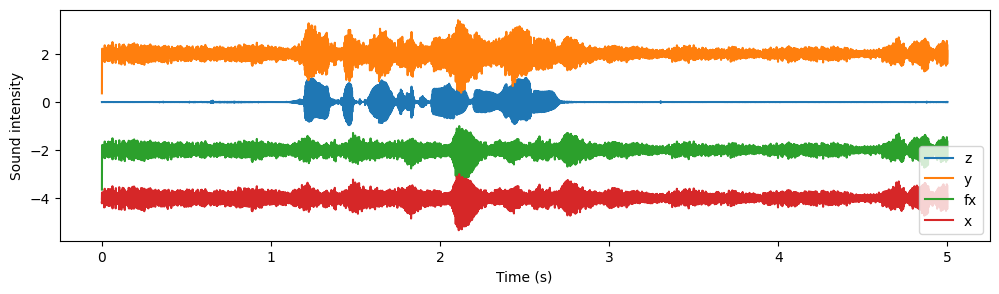

In [ ]:
plt.figure(figsize = (12,3))
t = np.arange(0,len(y))/framerate

plt.plot(t,z, label='z')
plt.plot(t,y+2, label='y')
plt.plot(t,fx-2, label='fx')
plt.plot(t,x-4, label='x')
plt.xlabel('Time (s)')
plt.ylabel('Sound intensity')
plt.legend()


Now your job is to create a network that is trained with input $x$ (external microphone) and output $y$ (internal microphone).  This will give you an estimate of $\hat{fx}$ because the network will have no way to predict $z$.  Then subtract $\hat{y}=\hat{fx}$ (network output) from $y$ to get
\begin{equation}
  \hat{z} = y-\hat{y} = fx+z - \hat{fx} = z + (fx - \hat{fx})
\end{equation}
Remember to use separate training and test sets, otherwise the network could potentially memorize the speech signal.  Listen to and plot the output for the test set.

Note:  there are pauses between words in the speech data.  Make sure the training and test data include at least some words.